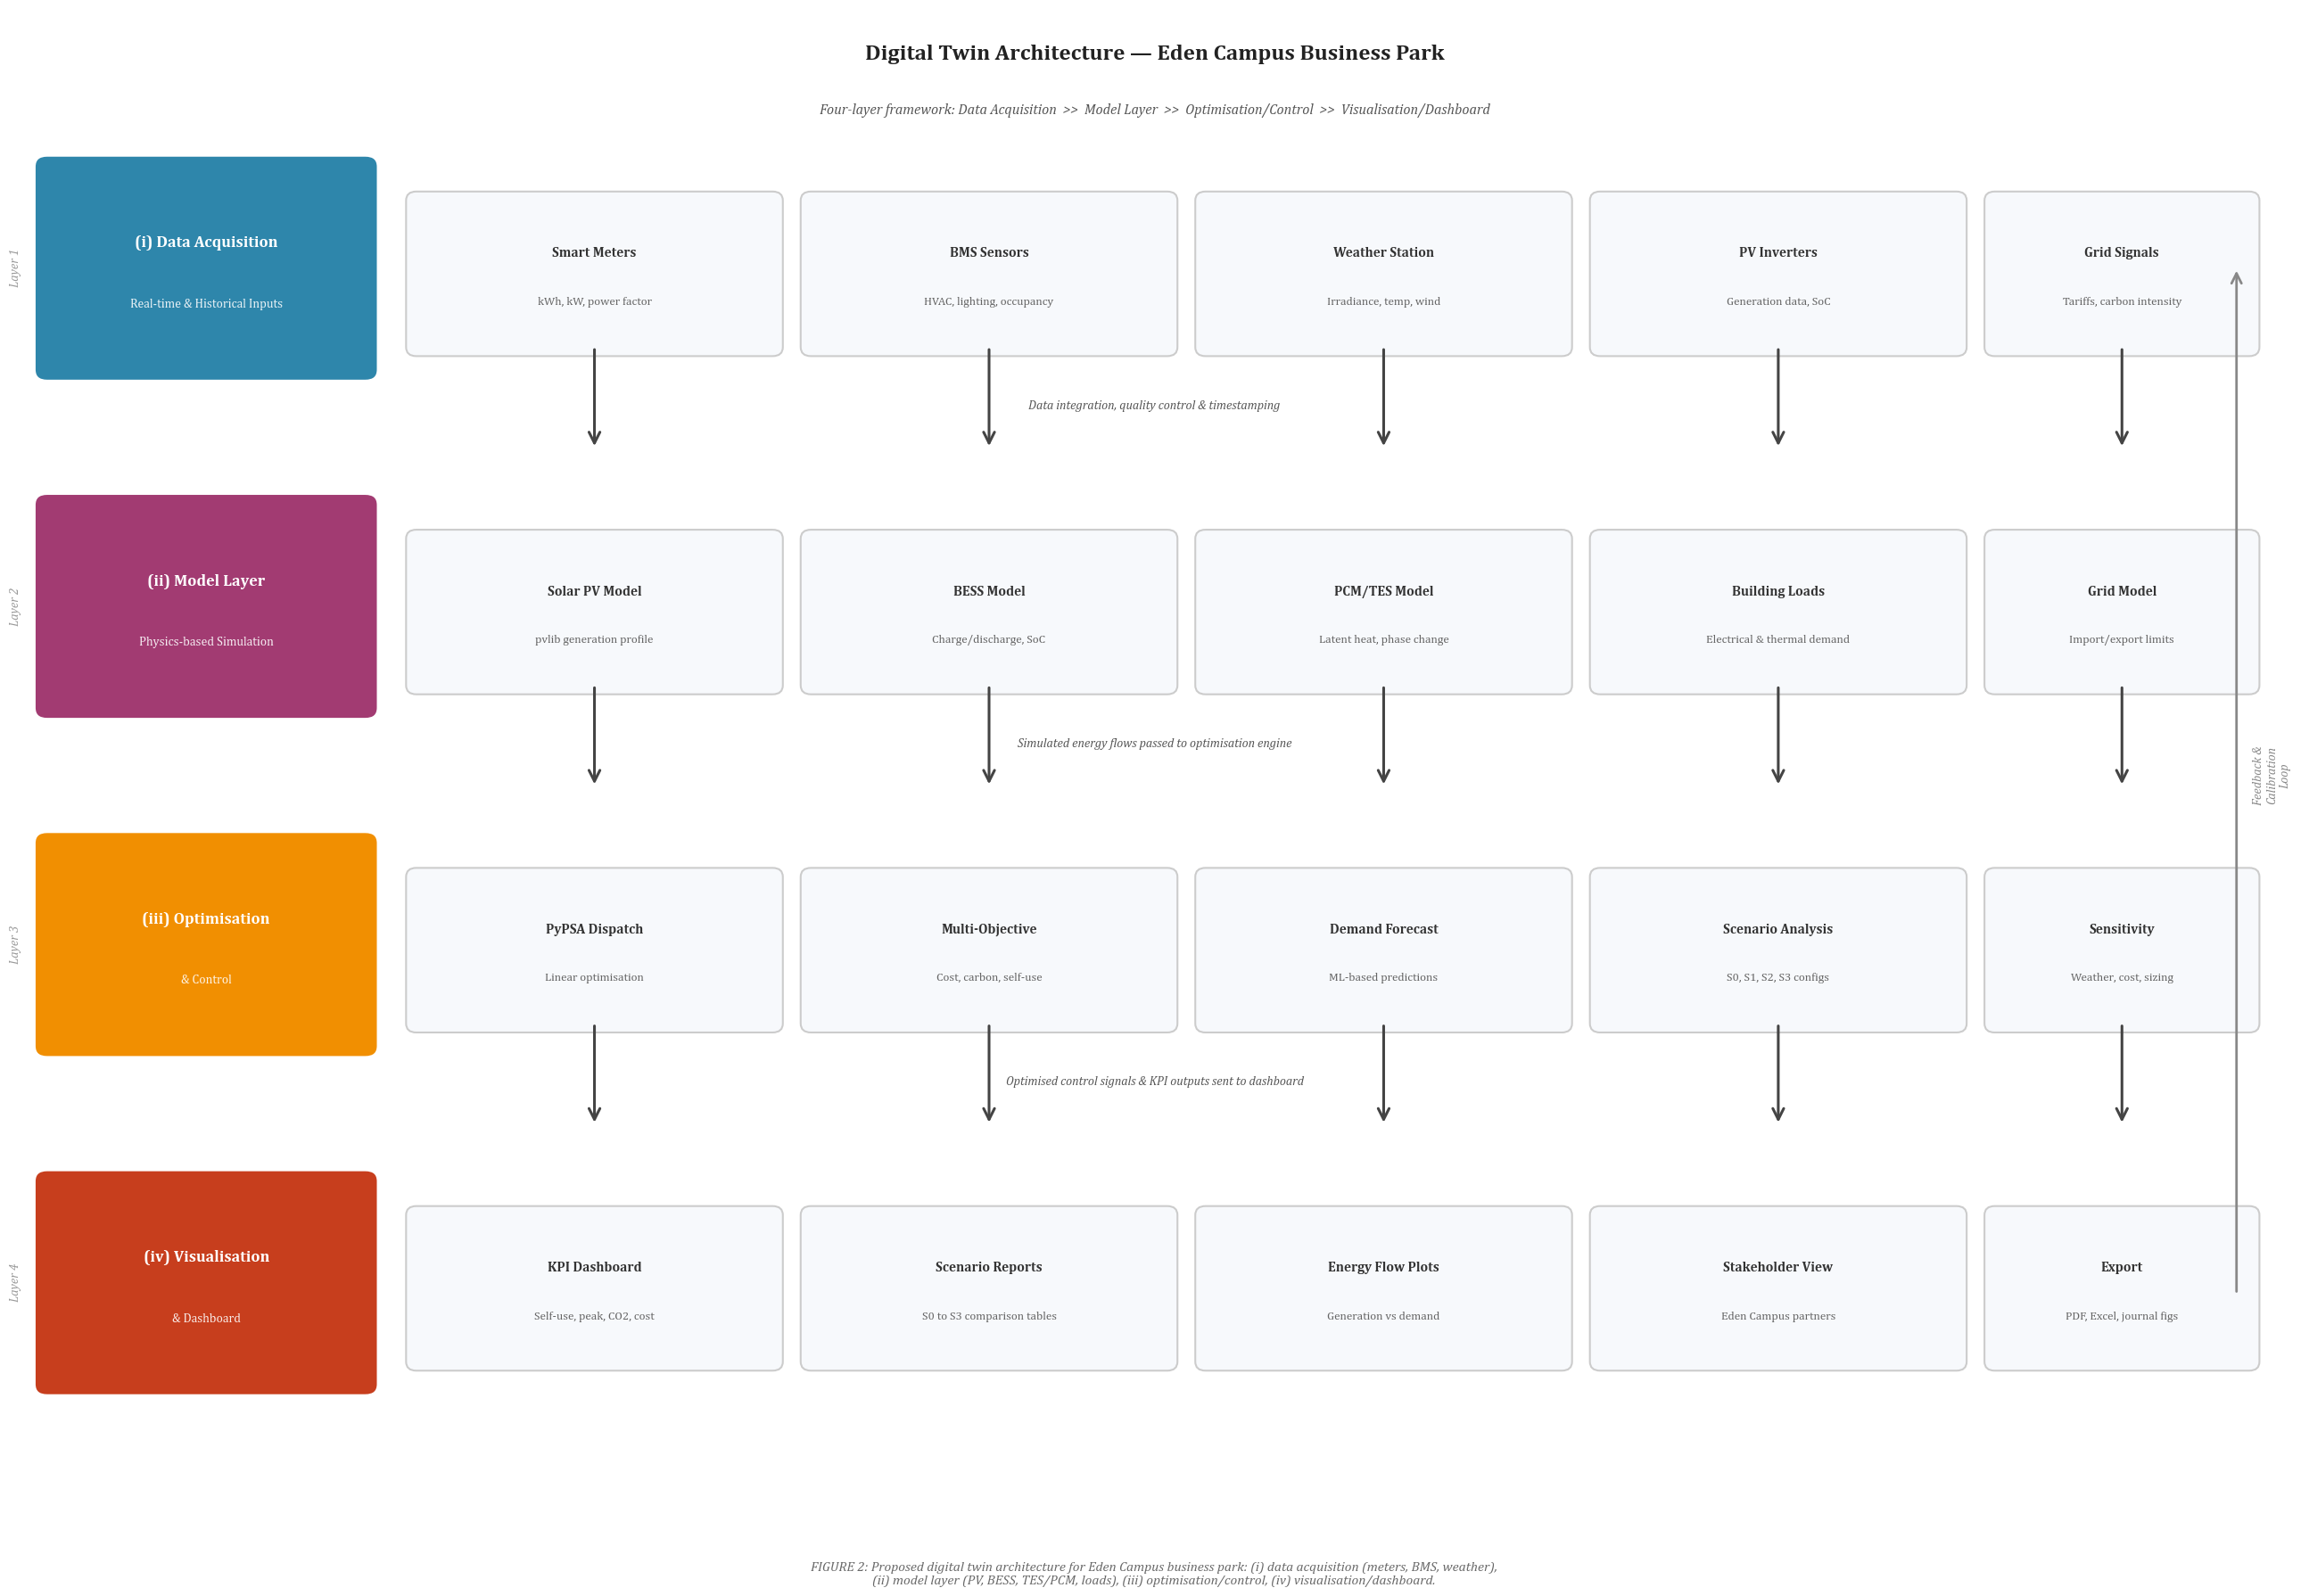

Stage 5 complete — Figure 2 saved!


In [1]:
import os
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import logging
import warnings

logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

base = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")

fig, ax = plt.subplots(1, 1, figsize=(26, 18))
ax.set_xlim(0, 18)
ax.set_ylim(0, 14)
ax.axis('off')

colors = {
    'layer1': '#2E86AB', 'layer2': '#A23B72',
    'layer3': '#F18F01', 'layer4': '#C73E1D',
    'box_bg': '#F7F9FC', 'arrow':  '#444444', 'border': '#CCCCCC',
}

def draw_layer_box(ax, x, y, width, height, color, label, sublabel=''):
    ax.add_patch(FancyBboxPatch((x, y), width, height,
                  boxstyle="round,pad=0.1", facecolor=color,
                  edgecolor='white', linewidth=2, zorder=2))
    ax.text(x + width/2, y + height/2 + (0.22 if sublabel else 0),
            label, ha='center', va='center', fontsize=13,
            fontweight='bold', color='white', zorder=3)
    if sublabel:
        ax.text(x + width/2, y + height/2 - 0.32, sublabel,
                ha='center', va='center', fontsize=10,
                color='white', alpha=0.9, zorder=3)

def draw_component_box(ax, x, y, width, height, label, sublabel=''):
    ax.add_patch(FancyBboxPatch((x, y), width, height,
                  boxstyle="round,pad=0.08", facecolor=colors['box_bg'],
                  edgecolor=colors['border'], linewidth=1.5, zorder=2))
    ax.text(x + width/2, y + height/2 + (0.18 if sublabel else 0),
            label, ha='center', va='center', fontsize=11,
            fontweight='bold', color='#333333', zorder=3)
    if sublabel:
        ax.text(x + width/2, y + height/2 - 0.25, sublabel,
                ha='center', va='center', fontsize=9.5,
                color='#666666', zorder=3)

def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=colors['arrow'],
                                lw=2.2, mutation_scale=22), zorder=4)

ax.text(9, 13.6, 'Digital Twin Architecture — Eden Campus Business Park',
        ha='center', va='center', fontsize=18, fontweight='bold', color='#222222')
ax.text(9, 13.1,
        'Four-layer framework: Data Acquisition  >>  Model Layer  >>  '
        'Optimisation/Control  >>  Visualisation/Dashboard',
        ha='center', va='center', fontsize=11.5, color='#555555', style='italic')

draw_layer_box(ax, 0.3, 10.8, 2.5, 1.8, colors['layer1'],
               '(i) Data Acquisition', 'Real-time & Historical Inputs')
for comp in [
    (3.2,  11.0, 2.8, 1.3, 'Smart Meters',    'kWh, kW, power factor'),
    (6.3,  11.0, 2.8, 1.3, 'BMS Sensors',     'HVAC, lighting, occupancy'),
    (9.4,  11.0, 2.8, 1.3, 'Weather Station', 'Irradiance, temp, wind'),
    (12.5, 11.0, 2.8, 1.3, 'PV Inverters',    'Generation data, SoC'),
    (15.6, 11.0, 2.0, 1.3, 'Grid Signals',    'Tariffs, carbon intensity'),
]:
    draw_component_box(ax, *comp)
for x in [4.6, 7.7, 10.8, 13.9, 16.6]:
    draw_arrow(ax, x, 11.0, x, 10.1)
ax.text(9, 10.48, 'Data integration, quality control & timestamping',
        ha='center', va='center', fontsize=10, color='#555555', style='italic')

draw_layer_box(ax, 0.3, 7.8, 2.5, 1.8, colors['layer2'],
               '(ii) Model Layer', 'Physics-based Simulation')
for comp in [
    (3.2,  8.0, 2.8, 1.3, 'Solar PV Model',  'pvlib generation profile'),
    (6.3,  8.0, 2.8, 1.3, 'BESS Model',       'Charge/discharge, SoC'),
    (9.4,  8.0, 2.8, 1.3, 'PCM/TES Model',    'Latent heat, phase change'),
    (12.5, 8.0, 2.8, 1.3, 'Building Loads',   'Electrical & thermal demand'),
    (15.6, 8.0, 2.0, 1.3, 'Grid Model',       'Import/export limits'),
]:
    draw_component_box(ax, *comp)
for x in [4.6, 7.7, 10.8, 13.9, 16.6]:
    draw_arrow(ax, x, 8.0, x, 7.1)
ax.text(9, 7.48, 'Simulated energy flows passed to optimisation engine',
        ha='center', va='center', fontsize=10, color='#555555', style='italic')

draw_layer_box(ax, 0.3, 4.8, 2.5, 1.8, colors['layer3'],
               '(iii) Optimisation', '& Control')
for comp in [
    (3.2,  5.0, 2.8, 1.3, 'PyPSA Dispatch',    'Linear optimisation'),
    (6.3,  5.0, 2.8, 1.3, 'Multi-Objective',   'Cost, carbon, self-use'),
    (9.4,  5.0, 2.8, 1.3, 'Demand Forecast',   'ML-based predictions'),
    (12.5, 5.0, 2.8, 1.3, 'Scenario Analysis', 'S0, S1, S2, S3 configs'),
    (15.6, 5.0, 2.0, 1.3, 'Sensitivity',       'Weather, cost, sizing'),
]:
    draw_component_box(ax, *comp)
for x in [4.6, 7.7, 10.8, 13.9, 16.6]:
    draw_arrow(ax, x, 5.0, x, 4.1)
ax.text(9, 4.48, 'Optimised control signals & KPI outputs sent to dashboard',
        ha='center', va='center', fontsize=10, color='#555555', style='italic')

draw_layer_box(ax, 0.3, 1.8, 2.5, 1.8, colors['layer4'],
               '(iv) Visualisation', '& Dashboard')
for comp in [
    (3.2,  2.0, 2.8, 1.3, 'KPI Dashboard',    'Self-use, peak, CO2, cost'),
    (6.3,  2.0, 2.8, 1.3, 'Scenario Reports', 'S0 to S3 comparison tables'),
    (9.4,  2.0, 2.8, 1.3, 'Energy Flow Plots','Generation vs demand'),
    (12.5, 2.0, 2.8, 1.3, 'Stakeholder View', 'Eden Campus partners'),
    (15.6, 2.0, 2.0, 1.3, 'Export',           'PDF, Excel, journal figs'),
]:
    draw_component_box(ax, *comp)

ax.annotate('', xy=(17.5, 11.7), xytext=(17.5, 2.6),
            arrowprops=dict(arrowstyle='->', color='#888888',
                            lw=2.0, mutation_scale=20), zorder=4)
ax.text(17.78, 7.2, 'Feedback &\nCalibration\nLoop',
        ha='center', va='center', fontsize=10, color='#888888',
        style='italic', rotation=90)

for y, label in [(11.7,'Layer 1'),(8.7,'Layer 2'),
                  (5.7,'Layer 3'),(2.7,'Layer 4')]:
    ax.text(0.05, y, label, ha='center', va='center', fontsize=10,
            color='#999999', rotation=90, style='italic')

fig.text(0.5, 0.01,
         'FIGURE 2: Proposed digital twin architecture for Eden Campus business park: '
         '(i) data acquisition (meters, BMS, weather),\n'
         '(ii) model layer (PV, BESS, TES/PCM, loads), '
         '(iii) optimisation/control, (iv) visualisation/dashboard.',
         ha='center', fontsize=11, style='italic', color='dimgray')

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures",
                          "figure2_digital_twin_architecture.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Stage 5 complete — Figure 2 saved!")

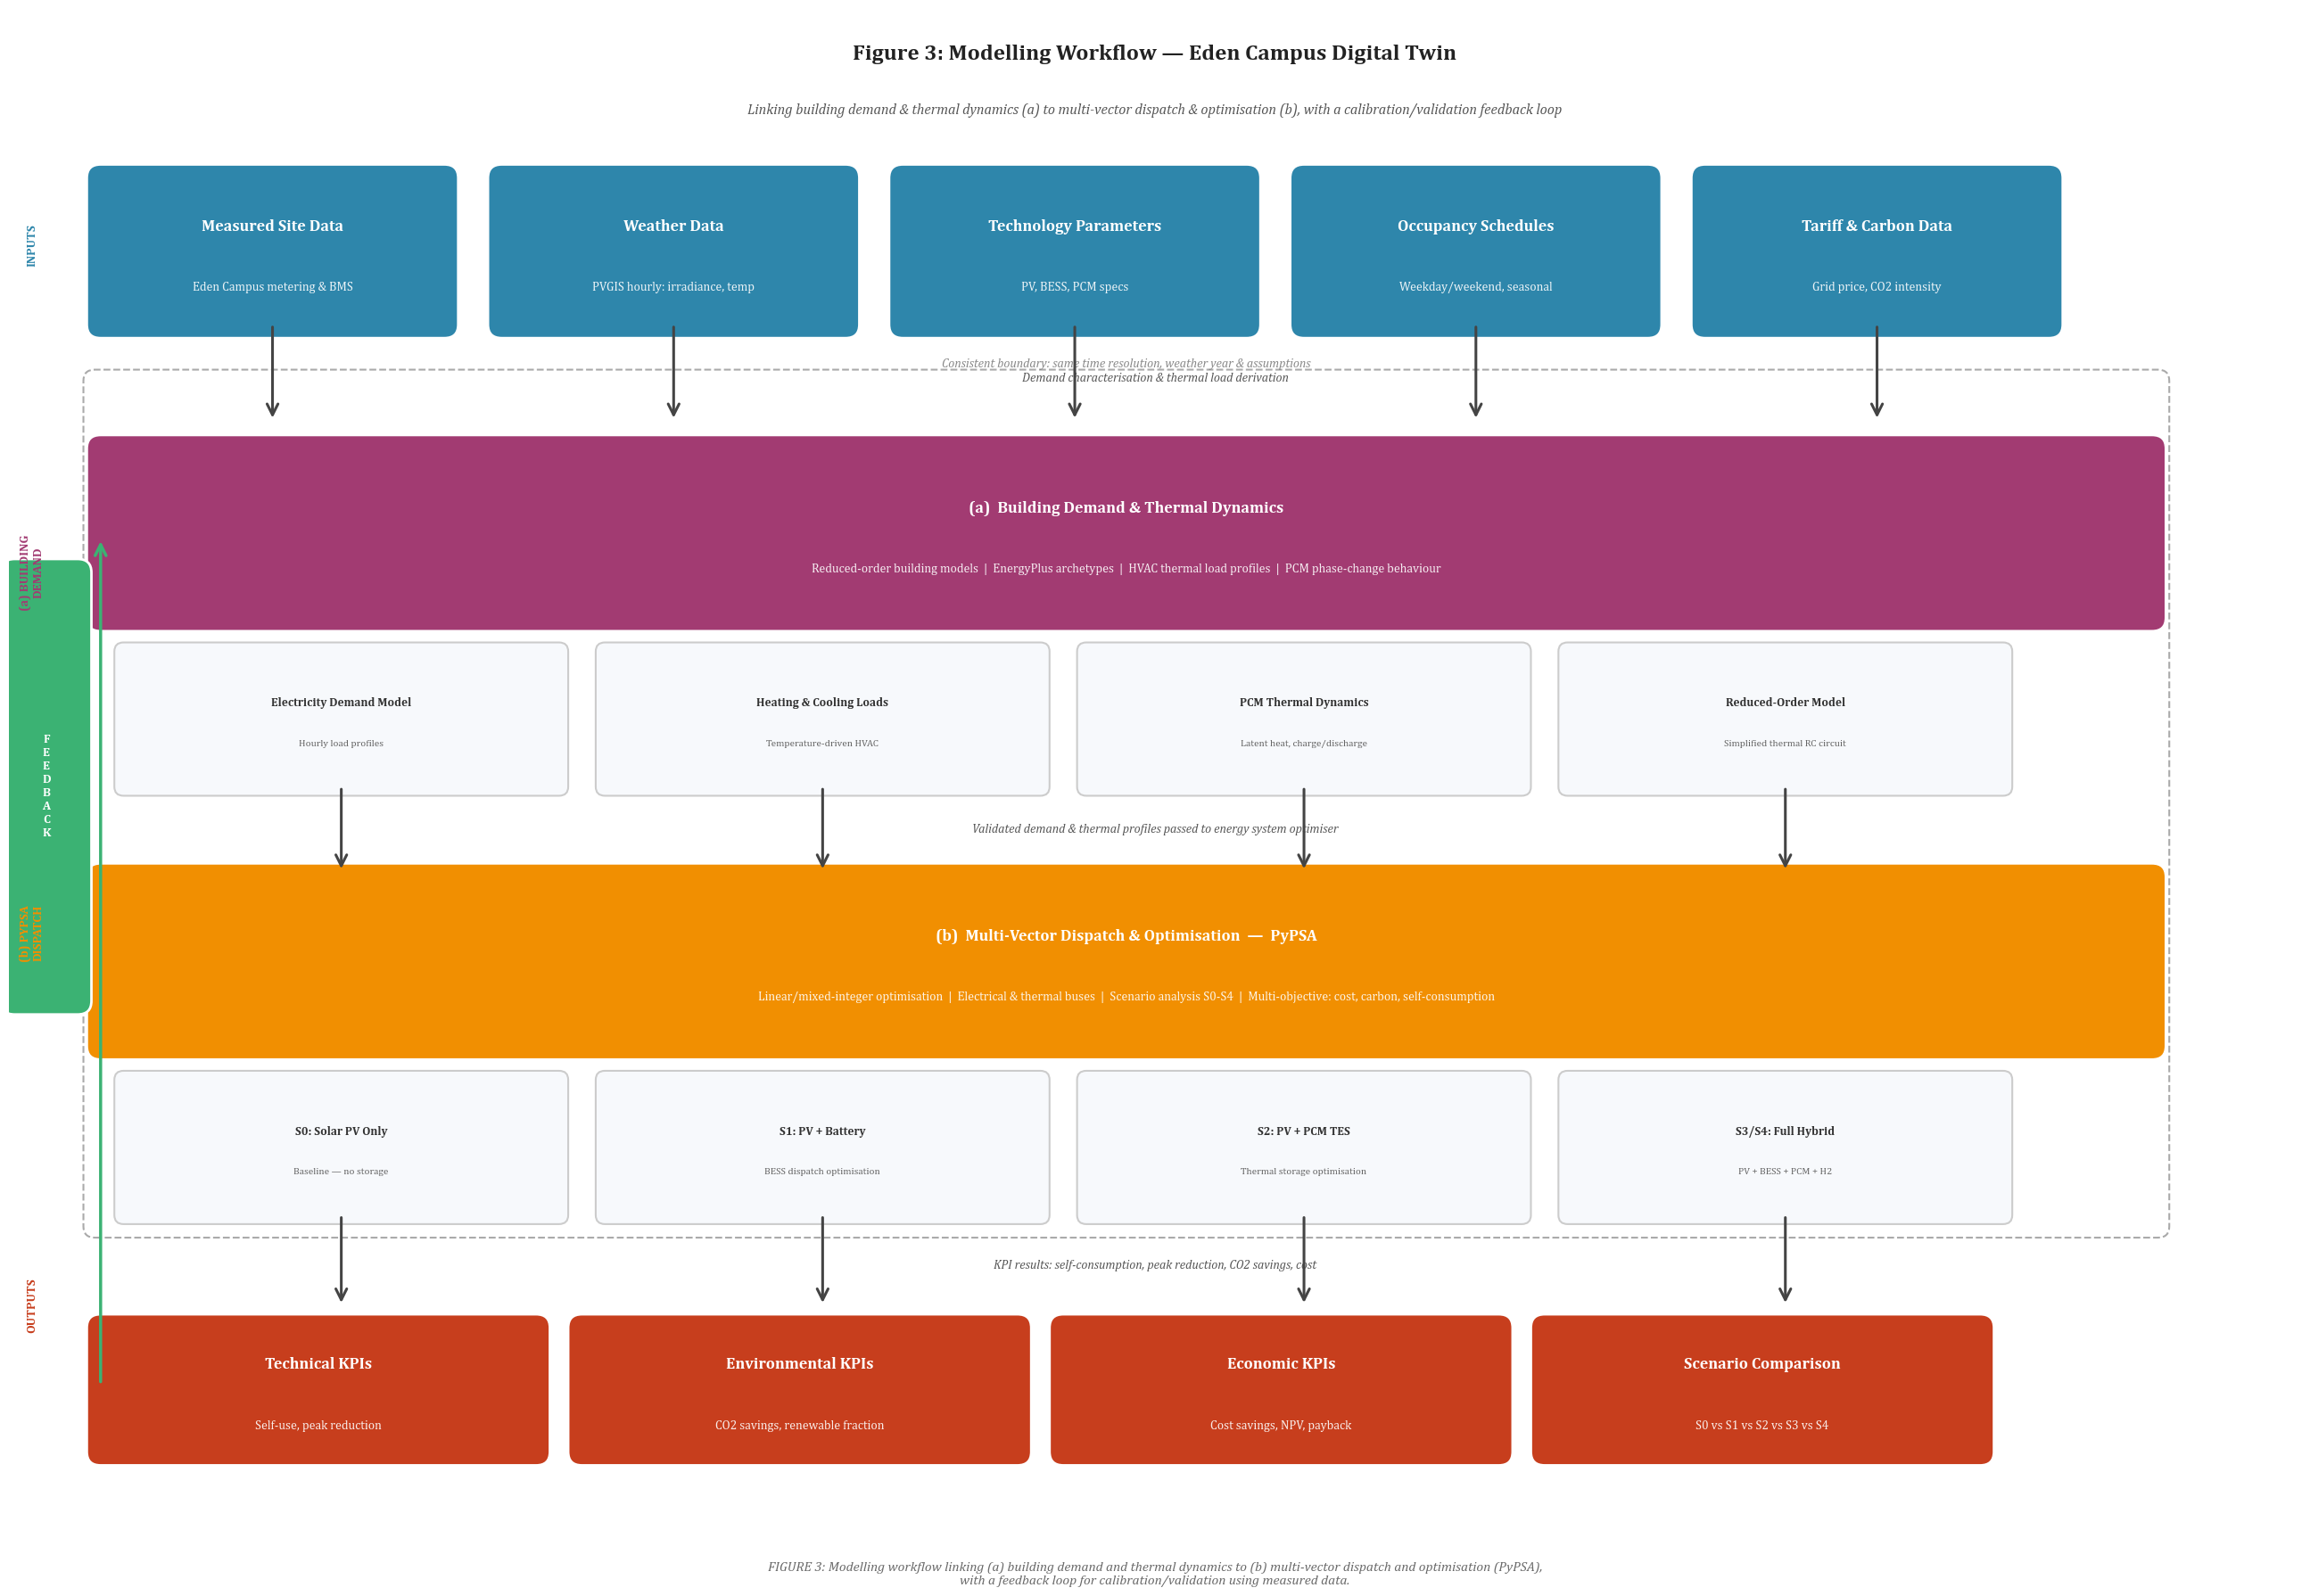

Stage 6 complete — Figure 3 saved!


In [6]:
import os
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import logging
import warnings

logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

base = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")

fig, ax = plt.subplots(1, 1, figsize=(26, 18))
ax.set_xlim(0, 20)
ax.set_ylim(0, 14)
ax.axis('off')

colors = {
    'inputs':   '#2E86AB', 'block_a':  '#A23B72',
    'block_b':  '#F18F01', 'feedback': '#3BB273',
    'outputs':  '#C73E1D', 'box_bg':   '#F7F9FC',
    'border':   '#CCCCCC', 'arrow':    '#444444',
}

def draw_box(ax, x, y, width, height, color, label,
             sublabel='', text_color='white', fontsize=13):
    ax.add_patch(FancyBboxPatch((x, y), width, height,
                  boxstyle="round,pad=0.12", facecolor=color,
                  edgecolor='white', linewidth=2, zorder=2))
    ax.text(x + width/2, y + height/2 + (0.22 if sublabel else 0),
            label, ha='center', va='center', fontsize=fontsize,
            fontweight='bold', color=text_color, zorder=3)
    if sublabel:
        ax.text(x + width/2, y + height/2 - 0.32, sublabel,
                ha='center', va='center', fontsize=10,
                color=text_color, alpha=0.9, zorder=3)

def draw_component_box(ax, x, y, width, height, label, sublabel=''):
    ax.add_patch(FancyBboxPatch((x, y), width, height,
                  boxstyle="round,pad=0.08", facecolor=colors['box_bg'],
                  edgecolor=colors['border'], linewidth=1.5, zorder=2))
    ax.text(x + width/2, y + height/2 + (0.14 if sublabel else 0),
            label, ha='center', va='center', fontsize=9.5,
            fontweight='bold', color='#333333', zorder=3)
    if sublabel:
        ax.text(x + width/2, y + height/2 - 0.22, sublabel,
                ha='center', va='center', fontsize=8,
                color='#666666', zorder=3)

def arrow(ax, x1, y1, x2, y2, color='#444444', lw=2.2, label=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=lw, mutation_scale=22), zorder=5)
    if label:
        ax.text((x1+x2)/2 + 0.2, (y1+y2)/2, label,
                fontsize=9, color=color, style='italic', va='center')

def curved_arrow(ax, x1, y1, x2, y2, color='#444444', rad=0.3, lw=2.0):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=lw,
                                mutation_scale=20,
                                connectionstyle=f'arc3,rad={rad}'), zorder=5)

# ── TITLE ──
ax.text(10, 13.6, 'Figure 3: Modelling Workflow — Eden Campus Digital Twin',
        ha='center', va='center', fontsize=18, fontweight='bold', color='#222222')
ax.text(10, 13.1,
        'Linking building demand & thermal dynamics (a) to '
        'multi-vector dispatch & optimisation (b), '
        'with a calibration/validation feedback loop',
        ha='center', va='center', fontsize=11.5, color='#555555', style='italic')

# ── SECTION LABELS ──
for label, y, color in [
    ('INPUTS',          11.9, colors['inputs']),
    ('(a) BUILDING\nDEMAND', 9.0, colors['block_a']),
    ('(b) PYPSA\nDISPATCH',  5.8, colors['block_b']),
    ('OUTPUTS',          2.5, colors['outputs']),
]:
    ax.text(0.2, y, label, fontsize=10, color=color,
            fontweight='bold', rotation=90, va='center', ha='center')

# ── INPUT LAYER ──
for x, y, w, h, label, sublabel in [
    (0.8,  11.2, 3.0, 1.3, 'Measured Site Data',   'Eden Campus metering & BMS'),
    (4.3,  11.2, 3.0, 1.3, 'Weather Data',          'PVGIS hourly: irradiance, temp'),
    (7.8,  11.2, 3.0, 1.3, 'Technology Parameters', 'PV, BESS, PCM specs'),
    (11.3, 11.2, 3.0, 1.3, 'Occupancy Schedules',   'Weekday/weekend, seasonal'),
    (14.8, 11.2, 3.0, 1.3, 'Tariff & Carbon Data',  'Grid price, CO2 intensity'),
]:
    draw_box(ax, x, y, w, h, colors['inputs'], label, sublabel)

for x in [2.3, 5.8, 9.3, 12.8, 16.3]:
    arrow(ax, x, 11.2, x, 10.35)
ax.text(10, 10.72, 'Demand characterisation & thermal load derivation',
        ha='center', va='center', fontsize=10, color='#555555', style='italic')

# ── BLOCK A ──
draw_box(ax, 0.8, 8.6, 17.9, 1.5, colors['block_a'],
         '(a)  Building Demand & Thermal Dynamics',
         'Reduced-order building models  |  EnergyPlus archetypes  |  '
         'HVAC thermal load profiles  |  PCM phase-change behaviour')

for x, y, w, h, label, sublabel in [
    (1.0,  7.1, 3.8, 1.2, 'Electricity Demand Model', 'Hourly load profiles'),
    (5.2,  7.1, 3.8, 1.2, 'Heating & Cooling Loads',  'Temperature-driven HVAC'),
    (9.4,  7.1, 3.8, 1.2, 'PCM Thermal Dynamics',     'Latent heat, charge/discharge'),
    (13.6, 7.1, 3.8, 1.2, 'Reduced-Order Model',      'Simplified thermal RC circuit'),
]:
    draw_component_box(ax, x, y, w, h, label, sublabel)

for x in [2.9, 7.1, 11.3, 15.5]:
    arrow(ax, x, 7.1, x, 6.35)
ax.text(10, 6.72,
        'Validated demand & thermal profiles passed to energy system optimiser',
        ha='center', va='center', fontsize=10, color='#555555', style='italic')

# ── BLOCK B ──
draw_box(ax, 0.8, 4.8, 17.9, 1.5, colors['block_b'],
         '(b)  Multi-Vector Dispatch & Optimisation  —  PyPSA',
         'Linear/mixed-integer optimisation  |  Electrical & thermal buses  |  '
         'Scenario analysis S0-S4  |  Multi-objective: cost, carbon, self-consumption')

for x, y, w, h, label, sublabel in [
    (1.0,  3.3, 3.8, 1.2, 'S0: Solar PV Only',  'Baseline — no storage'),
    (5.2,  3.3, 3.8, 1.2, 'S1: PV + Battery',   'BESS dispatch optimisation'),
    (9.4,  3.3, 3.8, 1.2, 'S2: PV + PCM TES',   'Thermal storage optimisation'),
    (13.6, 3.3, 3.8, 1.2, 'S3/S4: Full Hybrid', 'PV + BESS + PCM + H2'),
]:
    draw_component_box(ax, x, y, w, h, label, sublabel)

for x in [2.9, 7.1, 11.3, 15.5]:
    arrow(ax, x, 3.3, x, 2.5)
ax.text(10, 2.85,
        'KPI results: self-consumption, peak reduction, CO2 savings, cost',
        ha='center', va='center', fontsize=10, color='#555555', style='italic')

# ── OUTPUT LAYER ──
for x, y, w, h, label, sublabel in [
    (0.8,  1.2, 3.8, 1.1, 'Technical KPIs',      'Self-use, peak reduction'),
    (5.0,  1.2, 3.8, 1.1, 'Environmental KPIs',  'CO2 savings, renewable fraction'),
    (9.2,  1.2, 3.8, 1.1, 'Economic KPIs',       'Cost savings, NPV, payback'),
    (13.4, 1.2, 3.8, 1.1, 'Scenario Comparison', 'S0 vs S1 vs S2 vs S3 vs S4'),
]:
    draw_box(ax, x, y, w, h, colors['outputs'], label, sublabel)

# ── FEEDBACK LOOP ──
ax.annotate('', xy=(0.8, 9.3), xytext=(0.8, 1.8),
            arrowprops=dict(arrowstyle='->', color=colors['feedback'],
                            lw=2.5, mutation_scale=22), zorder=5)
draw_box(ax, 0.05, 5.2, 0.55, 3.8, colors['feedback'],
         'F\nE\nE\nD\nB\nA\nC\nK', text_color='white', fontsize=10)

# ── BOUNDARY BOX ──
ax.add_patch(FancyBboxPatch((0.75, 3.2), 18.0, 7.5,
              boxstyle="round,pad=0.1", facecolor='none',
              edgecolor='#AAAAAA', linewidth=1.5,
              linestyle='--', zorder=1))
ax.text(9.75, 10.85,
        'Consistent boundary: same time resolution, weather year & assumptions',
        ha='center', va='center', fontsize=10, color='#888888', style='italic')

# ── CAPTION ──
fig.text(0.5, 0.01,
         'FIGURE 3: Modelling workflow linking (a) building demand and thermal dynamics '
         'to (b) multi-vector dispatch and optimisation (PyPSA),\n'
         'with a feedback loop for calibration/validation using measured data.',
         ha='center', fontsize=11, style='italic', color='dimgray')

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures", "figure3_modelling_workflow.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Stage 6 complete — Figure 3 saved!")

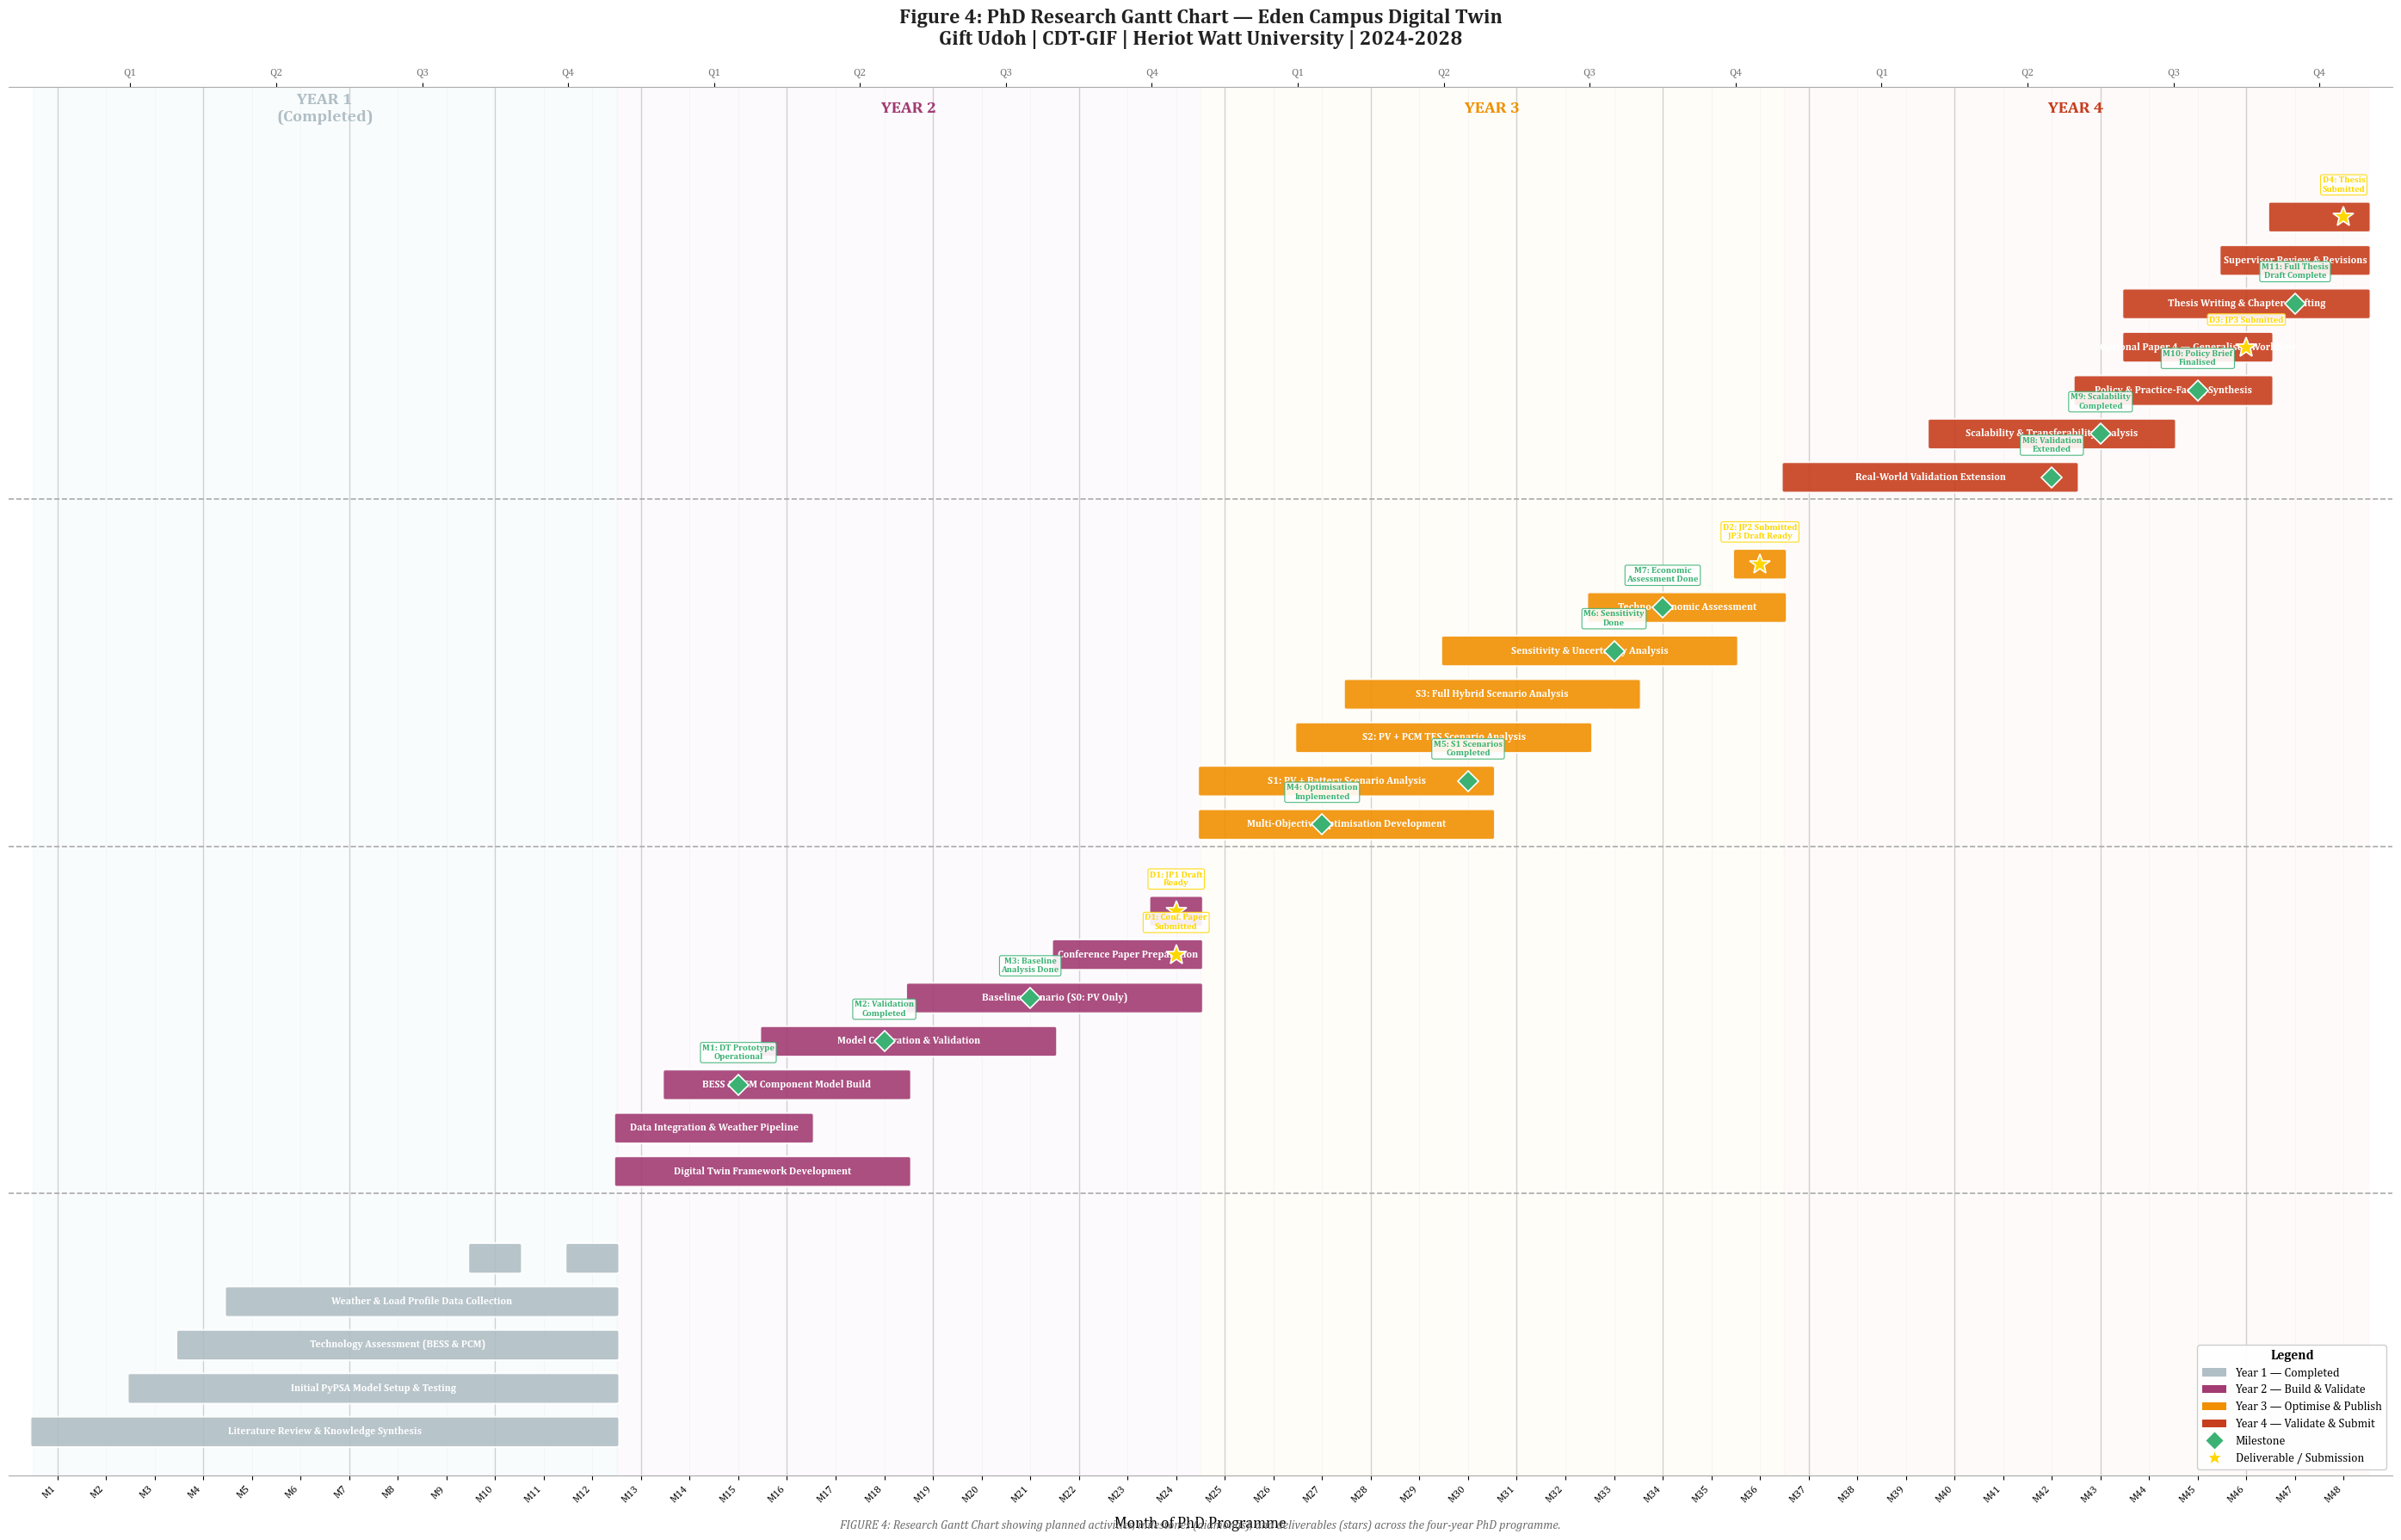

Stage 7 complete — Figure 4 saved!


In [9]:
import os
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np
import logging
import warnings

logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

base = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")

colors = {
    'year1':       '#B0BEC5',
    'year2':       '#A23B72',
    'year3':       '#F18F01',
    'year4':       '#C73E1D',
    'milestone':   '#3BB273',
    'deliverable': '#FFD700',
    'grid':        '#EEEEEE',
}

tasks = [
    ('Literature Review & Knowledge Synthesis',    1,  12, colors['year1'], 0),
    ('Initial PyPSA Model Setup & Testing',        3,  12, colors['year1'], 1),
    ('Technology Assessment (BESS & PCM)',          4,  12, colors['year1'], 2),
    ('Weather & Load Profile Data Collection',      5,  12, colors['year1'], 3),
    ('Hydrogen Scotland Poster (Winner)',          10,  10, colors['year1'], 4),
    ('IDRIC Annual Conference Poster',            12,  12, colors['year1'], 4),
    ('Digital Twin Framework Development',        13,  18, colors['year2'], 6),
    ('Data Integration & Weather Pipeline',       13,  16, colors['year2'], 7),
    ('BESS & PCM Component Model Build',          14,  18, colors['year2'], 8),
    ('Model Calibration & Validation',            16,  21, colors['year2'], 9),
    ('Baseline Scenario (S0: PV Only)',           19,  24, colors['year2'], 10),
    ('Conference Paper Preparation',             22,  24, colors['year2'], 11),
    ('Stakeholder Presentation — Eden Campus',   24,  24, colors['year2'], 12),
    ('Multi-Objective Optimisation Development', 25,  30, colors['year3'], 14),
    ('S1: PV + Battery Scenario Analysis',       25,  30, colors['year3'], 15),
    ('S2: PV + PCM TES Scenario Analysis',       27,  32, colors['year3'], 16),
    ('S3: Full Hybrid Scenario Analysis',        28,  33, colors['year3'], 17),
    ('Sensitivity & Uncertainty Analysis',       30,  35, colors['year3'], 18),
    ('Techno-Economic Assessment',               33,  36, colors['year3'], 19),
    ('Stakeholder Workshop — Eden Campus',       36,  36, colors['year3'], 20),
    ('Real-World Validation Extension',          37,  42, colors['year4'], 22),
    ('Scalability & Transferability Analysis',   40,  44, colors['year4'], 23),
    ('Policy & Practice-Facing Synthesis',       43,  46, colors['year4'], 24),
    ('Optional Paper 4 — Generalised Workflow',  44,  46, colors['year4'], 25),
    ('Thesis Writing & Chapter Drafting',        44,  48, colors['year4'], 26),
    ('Supervisor Review & Revisions',            46,  48, colors['year4'], 27),
    ('Thesis Submission & Viva Preparation',     47,  48, colors['year4'], 28),
]

milestones = [
    (15, 8,  'M1: DT Prototype\nOperational',     'milestone'),
    (18, 9,  'M2: Validation\nCompleted',          'milestone'),
    (21, 10, 'M3: Baseline\nAnalysis Done',        'milestone'),
    (24, 11, 'D1: Conf. Paper\nSubmitted',         'deliverable'),
    (24, 12, 'D1: JP1 Draft\nReady',               'deliverable'),
    (27, 14, 'M4: Optimisation\nImplemented',      'milestone'),
    (30, 15, 'M5: S1 Scenarios\nCompleted',        'milestone'),
    (33, 18, 'M6: Sensitivity\nDone',              'milestone'),
    (34, 19, 'M7: Economic\nAssessment Done',      'milestone'),
    (36, 20, 'D2: JP2 Submitted\nJP3 Draft Ready', 'deliverable'),
    (42, 22, 'M8: Validation\nExtended',           'milestone'),
    (43, 23, 'M9: Scalability\nCompleted',         'milestone'),
    (45, 24, 'M10: Policy Brief\nFinalised',       'milestone'),
    (46, 25, 'D3: JP3 Submitted',                  'deliverable'),
    (47, 26, 'M11: Full Thesis\nDraft Complete',   'milestone'),
    (48, 28, 'D4: Thesis\nSubmitted',              'deliverable'),
]

fig, ax = plt.subplots(figsize=(28, 18))
ax.set_xlim(0, 49)
ax.set_ylim(-1, 31)
ax.set_facecolor('white')

for start, end, bg, label, txt in [
    (1,  12, '#EBF5FB', 'YEAR 1\n(Completed)', colors['year1']),
    (13, 24, '#F5EEF8', 'YEAR 2',              colors['year2']),
    (25, 36, '#FEF9E7', 'YEAR 3',              colors['year3']),
    (37, 48, '#FDEDEC', 'YEAR 4',              colors['year4']),
]:
    ax.axvspan(start - 0.5, end + 0.5, alpha=0.25, color=bg, zorder=0)
    ax.text((start + end) / 2, 30.5, label,
            ha='center', va='center', fontsize=14,
            fontweight='bold', color=txt)

for month in range(1, 49):
    ax.axvline(month, color=colors['grid'], linewidth=0.5, alpha=0.7, zorder=0)
for month in range(1, 49, 3):
    ax.axvline(month, color='#CCCCCC', linewidth=1.0, alpha=0.9, zorder=0)

for task_label, start, end, color, row in tasks:
    duration = end - start + 1
    ax.add_patch(FancyBboxPatch(
        (start - 0.5, row - 0.3), duration, 0.6,
        boxstyle="round,pad=0.05", facecolor=color,
        edgecolor='white', linewidth=1.5, zorder=3, alpha=0.9))
    if duration >= 3:
        ax.text(start - 0.5 + duration / 2, row, task_label,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', zorder=4)

for month, row, label, mtype in milestones:
    marker_color = colors['milestone'] if mtype == 'milestone' else colors['deliverable']
    marker = 'D' if mtype == 'milestone' else '*'
    ms     = 12  if mtype == 'milestone' else 18
    ax.plot(month, row, marker=marker, color=marker_color,
            markersize=ms, zorder=6,
            markeredgecolor='white', markeredgewidth=1.2)
    ax.text(month, row + 0.55, label,
            ha='center', va='bottom', fontsize=7.5,
            color=marker_color, fontweight='bold', zorder=7,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                      edgecolor=marker_color, linewidth=0.8, alpha=0.9))

for y in [5.5, 13.5, 21.5]:
    ax.axhline(y, color='#AAAAAA', linewidth=1.2, linestyle='--', zorder=1)

ax.set_xticks(range(1, 49))
ax.set_xticklabels([f'M{m}' for m in range(1, 49)],
                    fontsize=8.5, rotation=45, ha='right')
ax.set_xlabel('Month of PhD Programme', fontsize=13, labelpad=10)
ax.set_yticks([])
for spine in ['left', 'right', 'top']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#AAAAAA')

ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks([2.5, 5.5, 8.5, 11.5, 14.5, 17.5, 20.5, 23.5,
                26.5, 29.5, 32.5, 35.5, 38.5, 41.5, 44.5, 47.5])
ax2.set_xticklabels(['Q1','Q2','Q3','Q4'] * 4,
                     fontsize=9, color='#777777')
for spine in ['left', 'right', 'bottom']:
    ax2.spines[spine].set_visible(False)
ax2.spines['top'].set_color('#AAAAAA')

ax.set_title(
    'Figure 4: PhD Research Gantt Chart — Eden Campus Digital Twin\n'
    'Gift Udoh | CDT-GIF | Heriot Watt University | 2024-2028',
    fontsize=17, fontweight='bold', color='#222222', pad=35)

ax.legend(handles=[
    mpatches.Patch(facecolor=colors['year1'],  label='Year 1 — Completed'),
    mpatches.Patch(facecolor=colors['year2'],  label='Year 2 — Build & Validate'),
    mpatches.Patch(facecolor=colors['year3'],  label='Year 3 — Optimise & Publish'),
    mpatches.Patch(facecolor=colors['year4'],  label='Year 4 — Validate & Submit'),
    plt.Line2D([0],[0], marker='D', color='w',
               markerfacecolor=colors['milestone'],
               markersize=11, label='Milestone'),
    plt.Line2D([0],[0], marker='*', color='w',
               markerfacecolor=colors['deliverable'],
               markersize=14, label='Deliverable / Submission'),
], loc='lower right', fontsize=10, framealpha=0.95,
   edgecolor='#CCCCCC', title='Legend',
   title_fontproperties={'size': 11, 'weight': 'bold'})

fig.text(0.5, 0.01,
         'FIGURE 4: Research Gantt Chart showing planned activities, '
         'milestones (diamonds), and deliverables (stars) '
         'across the four-year PhD programme.',
         ha='center', fontsize=10, style='italic', color='dimgray')

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures", "figure4_gantt_chart.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Stage 7 complete — Figure 4 saved!")

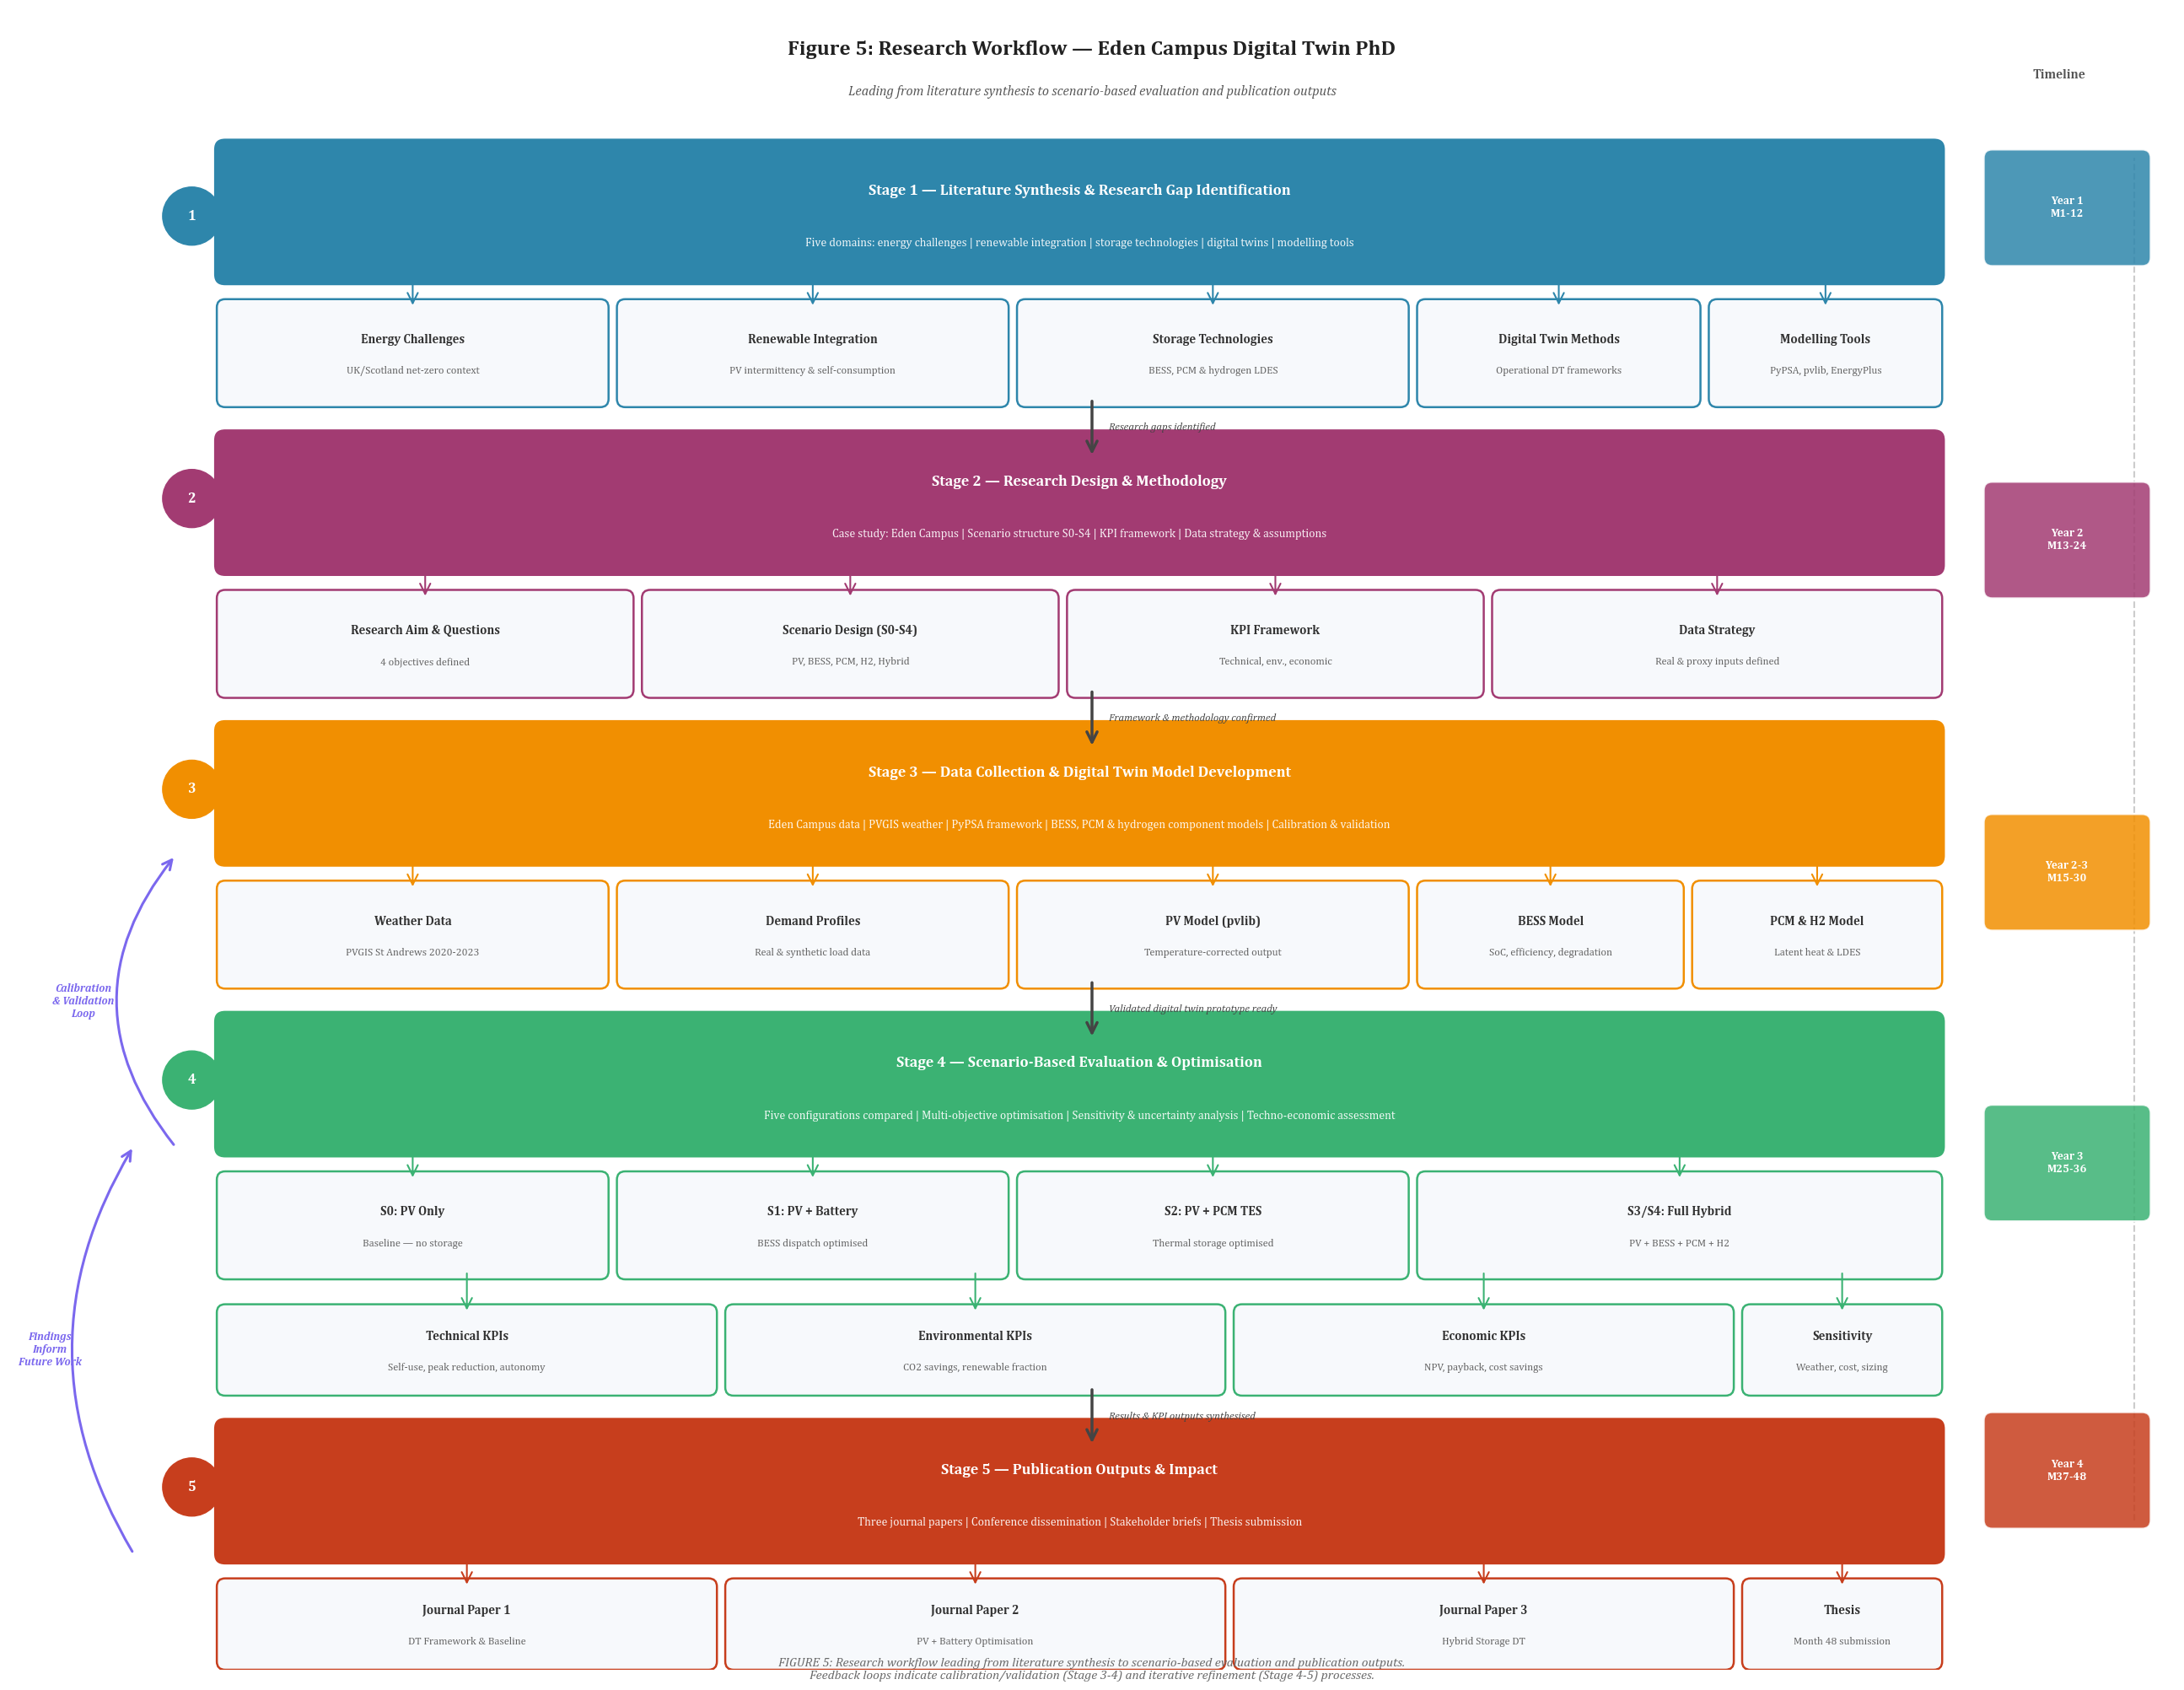

Stage 8 complete — Figure 5 saved!


In [10]:
import os
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import logging
import warnings

logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

base = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")

fig, ax = plt.subplots(1, 1, figsize=(26, 20))
ax.set_xlim(0, 26)
ax.set_ylim(0, 20)
ax.axis('off')

colors = {
    'stage1': '#2E86AB', 'stage2': '#A23B72',
    'stage3': '#F18F01', 'stage4': '#3BB273',
    'stage5': '#C73E1D', 'box_bg': '#F7F9FC',
    'border': '#CCCCCC', 'feedback': '#7B68EE',
}

def draw_main_box(ax, x, y, w, h, color, label, sublabel='', fontsize=13):
    ax.add_patch(FancyBboxPatch((x, y), w, h,
                  boxstyle="round,pad=0.15", facecolor=color,
                  edgecolor='white', linewidth=2.5, zorder=2))
    ax.text(x + w/2, y + h/2 + (0.25 if sublabel else 0),
            label, ha='center', va='center', fontsize=fontsize,
            fontweight='bold', color='white', zorder=3)
    if sublabel:
        ax.text(x + w/2, y + h/2 - 0.38, sublabel,
                ha='center', va='center', fontsize=10,
                color='white', alpha=0.92, zorder=3)

def draw_sub_box(ax, x, y, w, h, label, sublabel='', border_color='#CCCCCC'):
    ax.add_patch(FancyBboxPatch((x, y), w, h,
                  boxstyle="round,pad=0.1", facecolor=colors['box_bg'],
                  edgecolor=border_color, linewidth=1.8, zorder=2))
    ax.text(x + w/2, y + h/2 + (0.16 if sublabel else 0),
            label, ha='center', va='center', fontsize=10.5,
            fontweight='bold', color='#333333', zorder=3)
    if sublabel:
        ax.text(x + w/2, y + h/2 - 0.22, sublabel,
                ha='center', va='center', fontsize=9,
                color='#666666', zorder=3)

def arrow(ax, x1, y1, x2, y2, color='#444444', lw=2.2, label=''):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=lw, mutation_scale=22), zorder=5)
    if label:
        ax.text((x1+x2)/2 + 0.2, (y1+y2)/2, label,
                fontsize=9, color=color, style='italic', va='center')

def curved_arrow(ax, x1, y1, x2, y2, color='#444444', rad=0.3, lw=2.0):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=lw,
                                mutation_scale=20,
                                connectionstyle=f'arc3,rad={rad}'), zorder=5)

def step_label(ax, x, y, number, color):
    ax.add_patch(plt.Circle((x, y), 0.35, color=color, zorder=6))
    ax.text(x, y, str(number), ha='center', va='center',
            fontsize=12, fontweight='bold', color='white', zorder=7)

# ── TITLE ──
ax.text(13, 19.5,
        'Figure 5: Research Workflow — Eden Campus Digital Twin PhD',
        ha='center', va='center', fontsize=18,
        fontweight='bold', color='#222222')
ax.text(13, 19.0,
        'Leading from literature synthesis to scenario-based '
        'evaluation and publication outputs',
        ha='center', va='center', fontsize=11.5,
        color='#555555', style='italic')

# ── STAGE 1 ──
step_label(ax, 2.2, 17.5, '1', colors['stage1'])
draw_main_box(ax, 2.6, 16.8, 20.5, 1.5, colors['stage1'],
              'Stage 1 — Literature Synthesis & Research Gap Identification',
              'Five domains: energy challenges | renewable integration | '
              'storage technologies | digital twins | modelling tools')
for x, y, w, h, label, sublabel in [
    (2.6,  15.3, 4.5, 1.1, 'Energy Challenges',    'UK/Scotland net-zero context'),
    (7.4,  15.3, 4.5, 1.1, 'Renewable Integration', 'PV intermittency & self-consumption'),
    (12.2, 15.3, 4.5, 1.1, 'Storage Technologies',  'BESS, PCM & hydrogen LDES'),
    (17.0, 15.3, 3.2, 1.1, 'Digital Twin Methods',  'Operational DT frameworks'),
    (20.5, 15.3, 2.6, 1.1, 'Modelling Tools',       'PyPSA, pvlib, EnergyPlus'),
]:
    draw_sub_box(ax, x, y, w, h, label, sublabel,
                 border_color=colors['stage1'])
for x in [4.85, 9.65, 14.45, 18.6, 21.8]:
    arrow(ax, x, 16.8, x, 16.4, color=colors['stage1'], lw=1.5)
arrow(ax, 13, 15.3, 13, 14.6, color='#444444', lw=2.5,
      label='Research gaps identified')

# ── STAGE 2 ──
step_label(ax, 2.2, 14.1, '2', colors['stage2'])
draw_main_box(ax, 2.6, 13.3, 20.5, 1.5, colors['stage2'],
              'Stage 2 — Research Design & Methodology',
              'Case study: Eden Campus | Scenario structure S0-S4 | '
              'KPI framework | Data strategy & assumptions')
for x, y, w, h, label, sublabel in [
    (2.6,  11.8, 4.8, 1.1, 'Research Aim & Questions', '4 objectives defined'),
    (7.7,  11.8, 4.8, 1.1, 'Scenario Design (S0-S4)',  'PV, BESS, PCM, H2, Hybrid'),
    (12.8, 11.8, 4.8, 1.1, 'KPI Framework',            'Technical, env., economic'),
    (17.9, 11.8, 5.2, 1.1, 'Data Strategy',            'Real & proxy inputs defined'),
]:
    draw_sub_box(ax, x, y, w, h, label, sublabel,
                 border_color=colors['stage2'])
for x in [5.0, 10.1, 15.2, 20.5]:
    arrow(ax, x, 13.3, x, 12.9, color=colors['stage2'], lw=1.5)
arrow(ax, 13, 11.8, 13, 11.1, color='#444444', lw=2.5,
      label='Framework & methodology confirmed')

# ── STAGE 3 ──
step_label(ax, 2.2, 10.6, '3', colors['stage3'])
draw_main_box(ax, 2.6, 9.8, 20.5, 1.5, colors['stage3'],
              'Stage 3 — Data Collection & Digital Twin Model Development',
              'Eden Campus data | PVGIS weather | PyPSA framework | '
              'BESS, PCM & hydrogen component models | Calibration & validation')
for x, y, w, h, label, sublabel in [
    (2.6,  8.3, 4.5, 1.1, 'Weather Data',       'PVGIS St Andrews 2020-2023'),
    (7.4,  8.3, 4.5, 1.1, 'Demand Profiles',    'Real & synthetic load data'),
    (12.2, 8.3, 4.5, 1.1, 'PV Model (pvlib)',   'Temperature-corrected output'),
    (17.0, 8.3, 3.0, 1.1, 'BESS Model',         'SoC, efficiency, degradation'),
    (20.3, 8.3, 2.8, 1.1, 'PCM & H2 Model',     'Latent heat & LDES'),
]:
    draw_sub_box(ax, x, y, w, h, label, sublabel,
                 border_color=colors['stage3'])
for x in [4.85, 9.65, 14.45, 18.5, 21.7]:
    arrow(ax, x, 9.8, x, 9.4, color=colors['stage3'], lw=1.5)
arrow(ax, 13, 8.3, 13, 7.6, color='#444444', lw=2.5,
      label='Validated digital twin prototype ready')

# ── STAGE 4 ──
step_label(ax, 2.2, 7.1, '4', colors['stage4'])
draw_main_box(ax, 2.6, 6.3, 20.5, 1.5, colors['stage4'],
              'Stage 4 — Scenario-Based Evaluation & Optimisation',
              'Five configurations compared | Multi-objective optimisation | '
              'Sensitivity & uncertainty analysis | Techno-economic assessment')
for x, y, w, h, label, sublabel in [
    (2.6,  4.8, 4.5, 1.1, 'S0: PV Only',       'Baseline — no storage'),
    (7.4,  4.8, 4.5, 1.1, 'S1: PV + Battery',  'BESS dispatch optimised'),
    (12.2, 4.8, 4.5, 1.1, 'S2: PV + PCM TES',  'Thermal storage optimised'),
    (17.0, 4.8, 6.1, 1.1, 'S3/S4: Full Hybrid','PV + BESS + PCM + H2'),
]:
    draw_sub_box(ax, x, y, w, h, label, sublabel,
                 border_color=colors['stage4'])
for x in [4.85, 9.65, 14.45, 20.05]:
    arrow(ax, x, 6.3, x, 5.9, color=colors['stage4'], lw=1.5)
for x, y, w, h, label, sublabel in [
    (2.6,  3.4, 5.8, 0.9, 'Technical KPIs',     'Self-use, peak reduction, autonomy'),
    (8.7,  3.4, 5.8, 0.9, 'Environmental KPIs', 'CO2 savings, renewable fraction'),
    (14.8, 3.4, 5.8, 0.9, 'Economic KPIs',      'NPV, payback, cost savings'),
    (20.9, 3.4, 2.2, 0.9, 'Sensitivity',        'Weather, cost, sizing'),
]:
    draw_sub_box(ax, x, y, w, h, label, sublabel,
                 border_color=colors['stage4'])
for x in [5.5, 11.6, 17.7, 22.0]:
    arrow(ax, x, 4.8, x, 4.3, color=colors['stage4'], lw=1.5)
arrow(ax, 13, 3.4, 13, 2.7, color='#444444', lw=2.5,
      label='Results & KPI outputs synthesised')

# ── STAGE 5 ──
step_label(ax, 2.2, 2.2, '5', colors['stage5'])
draw_main_box(ax, 2.6, 1.4, 20.5, 1.5, colors['stage5'],
              'Stage 5 — Publication Outputs & Impact',
              'Three journal papers | Conference dissemination | '
              'Stakeholder briefs | Thesis submission')
for x, y, w, h, label, sublabel in [
    (2.6,  0.1, 5.8, 0.9, 'Journal Paper 1', 'DT Framework & Baseline'),
    (8.7,  0.1, 5.8, 0.9, 'Journal Paper 2', 'PV + Battery Optimisation'),
    (14.8, 0.1, 5.8, 0.9, 'Journal Paper 3', 'Hybrid Storage DT'),
    (20.9, 0.1, 2.2, 0.9, 'Thesis',          'Month 48 submission'),
]:
    draw_sub_box(ax, x, y, w, h, label, sublabel,
                 border_color=colors['stage5'])
for x in [5.5, 11.6, 17.7, 22.0]:
    arrow(ax, x, 1.4, x, 1.0, color=colors['stage5'], lw=1.5)

# ── FEEDBACK LOOPS ──
curved_arrow(ax, 2.0, 6.3, 2.0, 9.8,
             color=colors['feedback'], rad=-0.4, lw=2.2)
ax.text(0.9, 8.05, 'Calibration\n& Validation\nLoop',
        ha='center', va='center', fontsize=9.5,
        color=colors['feedback'], fontweight='bold', style='italic')

curved_arrow(ax, 1.5, 1.4, 1.5, 6.3,
             color=colors['feedback'], rad=-0.3, lw=2.2)
ax.text(0.5, 3.85, 'Findings\nInform\nFuture Work',
        ha='center', va='center', fontsize=9.5,
        color=colors['feedback'], fontweight='bold', style='italic')

# ── TIMELINE BAR ──
ax.text(24.6, 19.2, 'Timeline', ha='center', va='center',
        fontsize=11, fontweight='bold', color='#555555')
for x, y, label, color in [
    (23.8, 17.0, 'Year 1\nM1-12',    colors['stage1']),
    (23.8, 13.0, 'Year 2\nM13-24',   colors['stage2']),
    (23.8,  9.0, 'Year 2-3\nM15-30', colors['stage3']),
    (23.8,  5.5, 'Year 3\nM25-36',   colors['stage4']),
    (23.8,  1.8, 'Year 4\nM37-48',   colors['stage5']),
]:
    ax.add_patch(FancyBboxPatch((x, y), 1.8, 1.2,
                  boxstyle="round,pad=0.1", facecolor=color,
                  edgecolor='white', linewidth=1.5, alpha=0.85, zorder=2))
    ax.text(x + 0.9, y + 0.6, label, ha='center', va='center',
            fontsize=9.5, fontweight='bold', color='white', zorder=3)
ax.plot([25.5, 25.5], [1.8, 18.2], color='#CCCCCC',
        linewidth=1.5, linestyle='--', zorder=1)

fig.text(0.5, 0.002,
         'FIGURE 5: Research workflow leading from literature synthesis '
         'to scenario-based evaluation and publication outputs.\n'
         'Feedback loops indicate calibration/validation (Stage 3-4) '
         'and iterative refinement (Stage 4-5) processes.',
         ha='center', fontsize=11, style='italic', color='dimgray')

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures", "figure5_research_workflow.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Stage 8 complete — Figure 5 saved!")